# Chapter 55: Business Cycles, Propagation, Hysteresis, and Stagnation

This notebook reruns four worked examples from the chapter: the accelerator's investment spike, a multiplier-accelerator cycle from one shock, real-business-cycle propagation through capital, and hysteresis in unemployment. All examples are hypothetical, as in the book; a few extra input values are added for comparison. Two of the book's subscripts are printed as `mathrm` without a backslash; the equations below write them as `\mathrm`.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def accelerator(Y_prev, Y_new, v, delta, K0=None, unit_cost=1.0):
    """Gross investment under the accelerator, I^g = K* - K_{-1} + delta K_{-1}, with K* = v Y^e.

    accelerator-principle (chapter 55): v = 6, delta = 0.10, Y 8 then 9.5, unit cost 50,000.
    K0* = 48, baseline 0.10(48) = 4.8 units ($240,000); K1* = 57, I1 = (57 - 48) + 4.8 = 13.8
    ($690,000); capital after 0.9(48) + 13.8 = 57; next period 0.10(57) = 5.7 ($285,000).
    K0 defaults to v Y_prev (inherited stock matching desired capital). Returns a dict of
    units and dollar spending for the baseline, adjustment and following periods.
    """
    K0 = v * Y_prev if K0 is None else K0
    K_star0, K_star1 = v * Y_prev, v * Y_new
    base = (K_star0 - K0) + delta * K0
    adjust = (K_star1 - K0) + delta * K0
    K1 = (1 - delta) * K0 + adjust
    nxt = (K_star1 - K1) + delta * K1
    return {"K0": K0, "K_star0": K_star0, "K_star1": K_star1, "base": base, "adjust": adjust, "K1": K1,
            "next": nxt, "base_cost": base * unit_cost, "adjust_cost": adjust * unit_cost,
            "next_cost": nxt * unit_cost, "drop_cost": (adjust - nxt) * unit_cost,
            "output_change": Y_new / Y_prev - 1.0}


def samuelson_path(c, v, A_path, Y0):
    """Multiplier-accelerator path: C_t = c Y_{t-1}, I_t = v (C_t - C_{t-1}), Y_t = C_t + I_t + A_t.

    multiplier-accelerator-interaction (chapter 55): c = 0.5, v = 1.2, A = 24 with 36 in period 1,
    Y0 = 48 (steady state): Y1..Y5 = 60, 61.2, 55.32, 48.132, 43.7532. A_path[0] is period 0;
    the economy is at rest before period 1 (C_0 = c Y0). Returns lists Y, C, I indexed by period.
    """
    Y, C, I = [float(Y0)], [c * Y0], [0.0]
    for t in range(1, len(A_path)):
        Ct = c * Y[-1]
        It = v * (Ct - C[-1])
        Y.append(Ct + It + A_path[t])
        C.append(Ct)
        I.append(It)
    return {"Y": Y, "C": C, "I": I}


def cobb_douglas(A, K, L, alpha):
    """Output A K^alpha L^(1 - alpha)."""
    return A * K ** alpha * L ** (1.0 - alpha)


plt.rcParams.update(HOUSE_RC)


macro = SimpleNamespace(accelerator=accelerator, samuelson_path=samuelson_path)


production = SimpleNamespace(cobb_douglas=cobb_douglas)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'accelerator-principle': {'v': 6,
                           'delta': 0.1,
                           'unit_cost': 50000,
                           'Y0': 8,
                           'Y1': 9.5,
                           'K_star0': 48,
                           'base': 4.8,
                           'base_cost': 240000,
                           'K_star1': 57,
                           'adjust': 13.8,
                           'adjust_cost': 690000,
                           'K1': 57,
                           'next': 5.7,
                           'next_cost': 285000,
                           'drop_cost': 405000,
                           'output_change_pct': 18.75},
 'multiplier-accelerator-interaction': {'c': 0.5,
                                        'v': 1.2,
                                        'A': 24,
                                        'A_shock': 36,
                                        'Y_bar': 48,
                                        'Y': [60, 61.2, 55.32, 48.132, 43.7532],
                                        'C4': 27.66,
                                        'I4': -3.528,
                                        'C5': 24.066,
                                        'I5': -4.3128},
 'real-business-cycle-propagation': {'alpha': 0.35,
                                     'Y': 100,
                                     'K': 160,
                                     'I0': 24,
                                     'I1': 28,
                                     'delta': 0.08,
                                     'z': 0.04,
                                     'z_next': 0.02,
                                     'n': 0.03,
                                     'K_next_0': 171.2,
                                     'K_next_1': 175.2,
                                     'ratio': 1.0602,
                                     'output': 106.02,
                                     'C1': 78.02,
                                     'C0': 76,
                                     'c_change_pct_printed_as': 2.66,
                                     'c_change_pct_exact_2dp': 2.65,
                                     'i_change_pct': 16.67,
                                     'ratio_next': 1.0283},
 'hysteresis-in-unemployment': {'labor_force': 24000,
                                'u_bar': 5,
                                'u0': 12.5,
                                'rho': 0.9,
                                'gamma': 0.25,
                                'u1': 6.875,
                                'unemployed_1': 1650,
                                'embedded': 450,
                                'gamma_program': 0.08333333333333333,
                                'u1_program': 5.625,
                                'unemployed_program': 1350},
 'constructed': {'accelerator-principle': {'Y1': [8, 9, 10], 'v': [4, 8]},
                 'multiplier-accelerator-interaction': {'c': [0.6, 0.75], 'v': [0.5, 2.0]},
                 'real-business-cycle-propagation': {'z': [0.02, 0.06], 'n': [0, 0.05]},
                 'hysteresis-in-unemployment': {'gamma': [0, 0.5], 'u0': [10, 15]}}}


def hysteresis_step(u_star, u_bar, u, rho, gamma):
    """hysteresis-in-unemployment: u*_{t+1} = u_bar + rho (u*_t - u_bar) + gamma (u_t - u*_t).

    Book: 5 + 0.9(5 - 5) + 0.25(12.5 - 5) = 6.875; with gamma = 1/12, 5.625.
    """
    return u_bar + rho * (u_star - u_bar) + gamma * (u - u_star)


def accelerator_picture(y1=9.5, v=6):
    b = BV["accelerator-principle"]
    y0, d, cost = b["Y0"], b["delta"], b["unit_cost"]
    r = macro.accelerator(y0, y1, v, d, None, cost)
    fig, ax = new_figure()
    vals = [r["base_cost"] / 1000, r["adjust_cost"] / 1000, r["next_cost"] / 1000]
    bar_compare(ax, ["Baseline", "Adjustment period", "Following period"], vals,
                colors=["grey", "terracotta", "teal"], value_labels=[money(1000 * x, 0) for x in vals],
                ylabel="Gross investment spending ($ thousand)", xlabel="Period")
    ax.set_ylim(0, 1_250)
    gap = r["K_star1"] - r["K0"]
    metrics = {"Desired capital before": num(r["K_star0"], 1), "Desired capital after": num(r["K_star1"], 1),
               "Baseline spending": money(r["base_cost"], 0), "Adjustment spending": money(r["adjust_cost"], 0),
               "Following-period spending": money(r["next_cost"], 0),
               "Drop after the gap closes": money(r["drop_cost"], 0),
               "Rise in expected output": f"{num(100 * r['output_change'])}%"}
    interp = (f"K* = {v} x 8 = {num(r['K_star0'], 1)} units, so baseline investment is 0.10 x {num(r['K0'], 1)} = "
              f"{num(r['base'], 2)} units, or {money(r['base_cost'], 0)}. With expected output {num(y1, 1)}, K* = {v} x "
              f"{num(y1, 1)} = {num(r['K_star1'], 1)}, and I = ({num(r['K_star1'], 1)} - {num(r['K0'], 1)}) + "
              f"{num(r['base'], 2)} = {num(r['adjust'], 2)} units, or {money(r['adjust_cost'], 0)}. "
              + (f"Once capital is {num(r['K1'], 1)}, spending falls back to replacement, "
                 if gap > 0 else f"With capital already at {num(r['K1'], 1)}, spending stays at replacement, ")
              + f"0.10 x {num(r['K1'], 1)} = {num(r['next'], 2)} units or {money(r['next_cost'], 0)}"
              + (f", a drop of {money(r['drop_cost'], 0)} while expected output stays at {num(y1, 1)}."
                 if gap > 0 else ": with no rise in expected output there is no investment spike."))
    steps = [f"K0* = {v} x 8 = {num(r['K_star0'], 1)}; baseline = 0.10 x {num(r['K0'], 1)} = {num(r['base'], 2)} units",
             f"K1* = {v} x {num(y1, 1)} = {num(r['K_star1'], 1)}",
             f"I1 = ({num(r['K_star1'], 1)} - {num(r['K0'], 1)}) + {num(r['base'], 2)} = {num(r['adjust'], 2)} units",
             f"Spending = {num(r['adjust'], 2)} x 50,000 = {money(r['adjust_cost'], 0)}",
             f"Next period = 0.10 x {num(r['K1'], 1)} = {num(r['next'], 2)} units = {money(r['next_cost'], 0)}"]
    alt = (f"Gross investment spending: baseline {money(r['base_cost'], 0)}, adjustment period "
           f"{money(r['adjust_cost'], 0)}, following period {money(r['next_cost'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def samuelson_picture(c=0.5, v=1.2):
    b = BV["multiplier-accelerator-interaction"]
    A, shock = b["A"], b["A_shock"]
    y_bar = A / (1 - c)
    path = [A] * 13
    path[1] = shock
    r = macro.samuelson_path(c, v, path, y_bar)
    Y, C, I = r["Y"], r["C"], r["I"]
    t = np.arange(13)
    fig, ax = new_figure()
    ax.plot(t, Y, color=PALETTE["navy"], linewidth=2.4, marker="o", markersize=4, label="income Y")
    ax.plot(t, C, color=PALETTE["teal"], linewidth=1.3, label="consumption C")
    ax.plot(t, I, color=PALETTE["gold"], linewidth=1.3, label="induced investment I")
    ax.axhline(y_bar, color=PALETTE["grey"], linestyle="dashed", linewidth=1.2,
               label=f"steady state {num(y_bar, 2)}")
    lo, hi = min(min(Y), min(I)), max(Y)
    span = hi - lo
    ax.set_ylim(lo - 0.1 * span, hi + 0.35 * span)
    ax.set_xlim(-0.5, 12.5)
    ax.legend(loc="upper right", frameon=False, ncol=2, fontsize=10)
    ax.set_xlabel("Period")
    ax.set_ylabel("Real expenditure")
    peak = int(np.argmax(Y))
    metrics = {"Steady state": num(y_bar, 4)}
    for k in range(1, 6):
        metrics[f"Y{k}"] = num(Y[k], 4)
    metrics["Peak period"] = str(peak)
    falls = Y[2] < Y[1]
    interp = (f"Steady state Y = 24 / (1 - {num(c, 2)}) = {num(y_bar, 4)}. Period 1: Y1 = {num(C[1], 4)} + 0 + 36 = "
              f"{num(Y[1], 4)}. Period 2: C2 = {num(c, 2)} x {num(Y[1], 4)} = {num(C[2], 4)}, I2 = {num(v, 1)} x "
              f"({num(C[2], 4)} - {num(C[1], 4)}) = {num(I[2], 4)}, so Y2 = {num(C[2], 4)} + {num(I[2], 4)} + 24 = "
              f"{num(Y[2], 4)}. "
              + ("Output keeps rising after the impulse ends, because investment responds to the rise in consumption."
                 if not falls else "Output falls as soon as the impulse ends: the induced investment is too small "
                 "to offset the lost autonomous spending."))
    steps = [f"Y = 24 / (1 - {num(c, 2)}) = {num(y_bar, 4)}",
             f"Y1 = {num(C[1], 4)} + 0 + 36 = {num(Y[1], 4)}",
             f"C2 = {num(c, 2)} x {num(Y[1], 4)} = {num(C[2], 4)}; I2 = {num(v, 1)} x ({num(C[2], 4)} - {num(C[1], 4)}) = {num(I[2], 4)}",
             f"Y2 = {num(C[2], 4)} + {num(I[2], 4)} + 24 = {num(Y[2], 4)}",
             f"C3 = {num(c, 2)} x {num(Y[2], 4)} = {num(C[3], 4)}; I3 = {num(v, 1)} x ({num(C[3], 4)} - {num(C[2], 4)}) = {num(I[3], 4)}",
             f"Y3 = {num(C[3], 4)} + {num(I[3], 4)} + 24 = {num(Y[3], 4)}"]
    alt = (f"Income path over 12 periods after a one-period rise in autonomous spending, with c = {num(c, 2)} and "
           f"v = {num(v, 1)}. Income starts at {num(y_bar, 2)}, reaches {num(Y[1], 2)} in period 1 and peaks at "
           f"{num(Y[peak], 2)} in period {peak}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def rbc_picture(z=0.04, n=0.03):
    b = BV["real-business-cycle-propagation"]
    alpha, K, I0, I1, d = b["alpha"], b["K"], b["I0"], b["I1"], b["delta"]
    ratio = production.cobb_douglas(1 + z, K, 1 + n, alpha) / production.cobb_douglas(1, K, 1, alpha)
    out = 100 * ratio
    c0, c1 = 100 - I0, out - I1
    k0, k1 = (1 - d) * K + I0, (1 - d) * K + I1
    z2 = z / 2
    ratio2 = production.cobb_douglas(1 + z2, k1, 1, alpha) / production.cobb_douglas(1, k0, 1, alpha)
    cap_part = (k1 / k0) ** alpha
    fig, (ax1, ax2) = new_figure(ncols=2)
    bar_compare(ax1, ["This period", "Next period"], [100 * (ratio - 1), 100 * (ratio2 - 1)],
                colors=["navy", "teal"], value_labels=[f"{num(100 * (ratio - 1))}%", f"{num(100 * (ratio2 - 1))}%"],
                ylabel="Output above no-shock path (%)", xlabel="Period")
    ax1.set_ylim(0, 11)
    parts = [100 * z2, 100 * ((1 + z2) * cap_part - (1 + z2))]
    bar_compare(ax2, ["Productivity", "Extra capital"], parts, colors=["gold", "olive"],
                value_labels=[f"{num(p)} pts" for p in parts], ylabel="Next-period gain (points)",
                xlabel="Source of next-period gain")
    ax2.set_ylim(0, 4.5)
    cg, ig = c1 / c0 - 1, I1 / I0 - 1
    metrics = {"Current output ratio": num(ratio, 4), "Output": num(out), "Consumption change": f"{num(100 * cg)}%",
               "Investment change": f"{num(100 * ig)}%", "Next-period capital": f"{num(k1, 1)} vs {num(k0, 1)}",
               "Next-period output ratio": num(ratio2, 4)}
    interp = (f"Capital is fixed this period, so Y1 / Y0 = {num(1 + z, 2)} x {num(1 + n, 2)}^0.65 = {num(ratio, 4)} and "
              f"output is {num(out)}. With investment at 28, consumption is {num(out, 4)} - 28 = {num(c1, 4)} against 76, a "
              f"change of {num(100 * cg)} percent, while investment rises {num(100 * ig)} percent. Next period capital "
              f"is 0.92 x 160 + 28 = {num(k1, 1)} against {num(k0, 1)}, and with productivity {num(100 * z2, 0)} "
              f"percent up the ratio is {num(1 + z2, 2)} x ({num(k1, 1)} / {num(k0, 1)})^0.35 = {num(ratio2, 4)}"
              + (f", more than the {num(100 * z2, 0)} percent productivity gain alone." if ratio2 > 1 + z2 else "."))
    steps = [f"K next (no shock) = 0.92 x 160 + 24 = {num(k0, 1)}",
             f"Y1 / Y0 = {num(1 + z, 2)} x {num(1 + n, 2)}^0.65 = {num(ratio, 4)}",
             f"C = {num(out, 4)} - 28 = {num(c1, 4)}; change = {num(c1, 4)} / 76 - 1 = {num(100 * cg)}%",
             f"K next (shock) = 0.92 x 160 + 28 = {num(k1, 1)}",
             f"Next ratio = {num(1 + z2, 2)} x ({num(k1, 1)} / {num(k0, 1)})^0.35 = {num(ratio2, 4)}"]
    alt = (f"Left: output is {num(100 * (ratio - 1))} percent above the no-shock path this period and "
           f"{num(100 * (ratio2 - 1))} percent next period. Right: next period's gain splits into "
           f"{num(parts[0])} points of productivity and {num(parts[1])} points from extra capital.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def gamma_text(g):
    return "1/12" if abs(g - 1 / 12) < 1e-12 else num(g, 2)


def hysteresis_picture(gamma=0.25, u0=12.5):
    b = BV["hysteresis-in-unemployment"]
    lf, u_bar, rho = b["labor_force"], b["u_bar"], b["rho"]
    u1 = hysteresis_step(u_bar, u_bar, u0, rho, gamma)
    count = u1 / 100 * lf
    base = u_bar / 100 * lf
    emb = count - base
    displaced = (u0 - u_bar) / 100 * lf
    fig, ax = new_figure()
    bar_compare(ax, ["Before recession", "Recession", "After recovery"], [u_bar, u0, u1],
                colors=["grey", "terracotta", "navy"], value_labels=[f"{num(u_bar, 3)}%", f"{num(u0, 3)}%", f"{num(u1, 3)}%"],
                ylabel="Unemployment rate (%)", xlabel="Stage")
    ax.set_ylim(0, 19)
    label(ax, 2, u1 / 2, f"{num(count, 0)} unemployed\n{num(emb, 0)} embedded", col="ink", dx=0, dy=0, ha="center",
          va="center")
    metrics = {"Equilibrium rate after recovery": f"{num(u1, 3)}%", "Unemployed after recovery": num(count, 0),
               "Embedded workers": num(emb, 0), "Displaced in the recession": num(displaced, 0)}
    g = gamma_text(gamma)
    interp = (f"u1* = 5 + 0.9 x (5 - 5) + {g} x ({num(u0, 1)} - 5) = 5 + {num(u1 - u_bar, 3)} = {num(u1, 3)} percent. "
              f"That is {num(u1 / 100, 5)} x 24,000 = {num(count, 0)} unemployed after demand recovers, "
              + (f"{num(emb, 0)} more than the original 1,200: the recession has left a scar."
                 if emb > 0.5 else "the same as the original 1,200: with no embedding there is no scar."))
    steps = [f"u1* = 5 + 0.9 x 0 + {g} x ({num(u0, 1)} - 5) = {num(u1, 3)}%",
             f"Unemployed = {num(u1 / 100, 5)} x 24,000 = {num(count, 0)}",
             f"Embedded = {num(count, 0)} - 1,200 = {num(emb, 0)}"]
    alt = (f"Unemployment rate before the recession 5 percent, in the recession {num(u0, 1)} percent and after "
           f"recovery {num(u1, 3)} percent, with {num(count, 0)} unemployed.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Accelerator principle: investment jumps on a demand rise

A plant with capital-output ratio $v=6$ and depreciation $\delta=0.10$ expects output 8 (in 10,000 cases), then 9.5. Each equipment unit costs \$50,000.

$$I_t^g=K_t^*-K_{t-1}+\delta K_{t-1}, \qquad I_{\mathrm{base}}^g=0+0.10(48)=4.8, \qquad I_1^g=(57-48)+0.10(48)=13.8$$

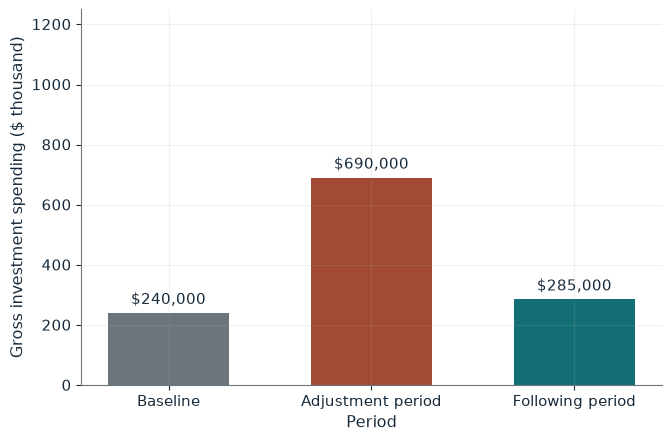

Desired capital before     48.0
Desired capital after      57.0
Baseline spending          $240,000
Adjustment spending        $690,000
Following-period spending  $285,000
Drop after the gap closes  $405,000
Rise in expected output    18.75%

Worked steps:
  1. K0* = 6 x 8 = 48.0; baseline = 0.10 x 48.0 = 4.80 units
  2. K1* = 6 x 9.5 = 57.0
  3. I1 = (57.0 - 48.0) + 4.80 = 13.80 units
  4. Spending = 13.80 x 50,000 = $690,000
  5. Next period = 0.10 x 57.0 = 5.70 units = $285,000

K* = 6 x 8 = 48.0 units, so baseline investment is 0.10 x 48.0 = 4.80 units, or $240,000. With expected output 9.5, K* = 6 x 9.5 = 57.0, and I = (57.0 - 48.0) + 4.80 = 13.80 units, or $690,000. Once capital is 57.0, spending falls back to replacement, 0.10 x 57.0 = 5.70 units or $285,000, a drop of $405,000 while expected output stays at 9.5.


In [2]:
show(accelerator_picture(y1=9.5, v=6))

Change one input, `y1`, and hold the others at the book's values:

In [3]:
sweep(accelerator_picture, 'y1', [8, 9, 9.5, 10], {'v': 6}, ['Adjustment spending', 'Following-period spending', 'Drop after the gap closes'])

y1 | Adjustment spending | Following-period spending | Drop after the gap closes
8 | $240,000 | $240,000 | $0
9 | $540,000 | $270,000 | $270,000
9.5 | $690,000 | $285,000 | $405,000
10 | $840,000 | $300,000 | $540,000


An 18.75 percent rise in expected output lifts gross spending from \$240,000 to \$690,000. Once the gap is closed, spending falls to replacement, \$285,000, while output stays high.

## 2. Multiplier-accelerator interaction: a single shock that cycles

With $c=0.5$, $v=1.2$ and $A=24$ (36 in period 1 only):

$$Y_t=c(1+v)Y_{t-1}-cvY_{t-2}+A_t, \qquad \bar Y=\frac{24}{1-0.5}=48$$

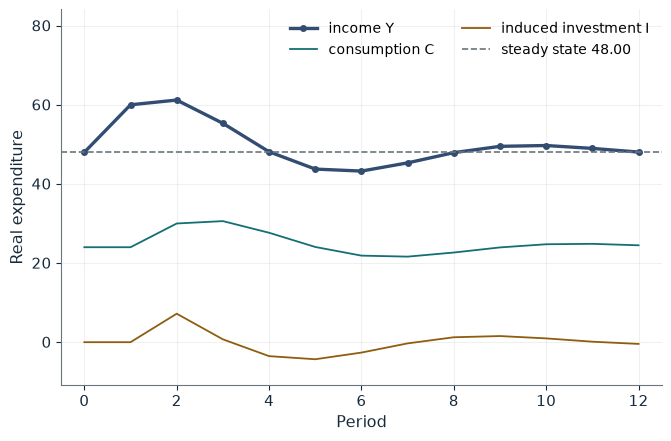

Steady state  48.0000
Y1            60.0000
Y2            61.2000
Y3            55.3200
Y4            48.1320
Y5            43.7532
Peak period   2

Worked steps:
  1. Y = 24 / (1 - 0.50) = 48.0000
  2. Y1 = 24.0000 + 0 + 36 = 60.0000
  3. C2 = 0.50 x 60.0000 = 30.0000; I2 = 1.2 x (30.0000 - 24.0000) = 7.2000
  4. Y2 = 30.0000 + 7.2000 + 24 = 61.2000
  5. C3 = 0.50 x 61.2000 = 30.6000; I3 = 1.2 x (30.6000 - 30.0000) = 0.7200
  6. Y3 = 30.6000 + 0.7200 + 24 = 55.3200

Steady state Y = 24 / (1 - 0.50) = 48.0000. Period 1: Y1 = 24.0000 + 0 + 36 = 60.0000. Period 2: C2 = 0.50 x 60.0000 = 30.0000, I2 = 1.2 x (30.0000 - 24.0000) = 7.2000, so Y2 = 30.0000 + 7.2000 + 24 = 61.2000. Output keeps rising after the impulse ends, because investment responds to the rise in consumption.


In [4]:
show(samuelson_picture(c=0.5, v=1.2))

Change one input, `v`, and hold the others at the book's values:

In [5]:
sweep(samuelson_picture, 'v', [0.5, 1.2, 2.0], {'c': 0.5}, ['Y1', 'Y2', 'Y3', 'Y4', 'Y5'])

v | Y1 | Y2 | Y3 | Y4 | Y5
0.5 | 60.0000 | 57.0000 | 51.7500 | 48.5625 | 47.4844
1.2 | 60.0000 | 61.2000 | 55.3200 | 48.1320 | 43.7532
2.0 | 60.0000 | 66.0000 | 63.0000 | 52.5000 | 39.7500


Output keeps rising to 61.2 after the impulse ends, then falls to 55.32, 48.132 and 43.7532, below the steady state: one shock produces a cycle.

## 3. Real-business-cycle propagation: a productivity shock that lingers

Capital share 0.35, output 100, capital 160, investment 24 (28 after the shock), depreciation 8 percent; productivity up 4 percent now and 2 percent next period, labor up 3 percent now.

$$\frac{Y_t^1}{Y_t^0}=1.04(1.03)^{0.65}\approx1.0602, \qquad \frac{Y_{t+1}^{1}}{Y_{t+1}^{0}}=1.02\left(\frac{175.2}{171.2}\right)^{0.35}\approx1.0283$$

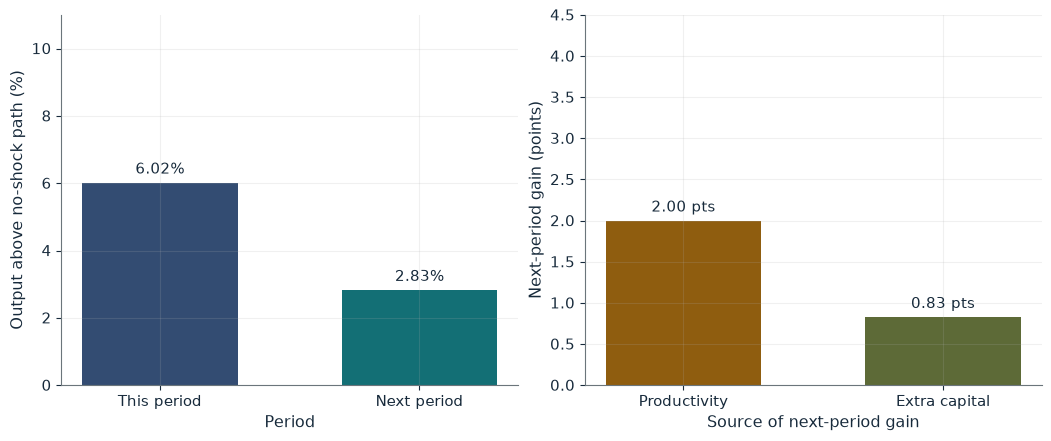

Current output ratio      1.0602
Output                    106.02
Consumption change        2.65%
Investment change         16.67%
Next-period capital       175.2 vs 171.2
Next-period output ratio  1.0283

Worked steps:
  1. K next (no shock) = 0.92 x 160 + 24 = 171.2
  2. Y1 / Y0 = 1.04 x 1.03^0.65 = 1.0602
  3. C = 106.0175 - 28 = 78.0175; change = 78.0175 / 76 - 1 = 2.65%
  4. K next (shock) = 0.92 x 160 + 28 = 175.2
  5. Next ratio = 1.02 x (175.2 / 171.2)^0.35 = 1.0283

Capital is fixed this period, so Y1 / Y0 = 1.04 x 1.03^0.65 = 1.0602 and output is 106.02. With investment at 28, consumption is 106.0175 - 28 = 78.0175 against 76, a change of 2.65 percent, while investment rises 16.67 percent. Next period capital is 0.92 x 160 + 28 = 175.2 against 171.2, and with productivity 2 percent up the ratio is 1.02 x (175.2 / 171.2)^0.35 = 1.0283, more than the 2 percent productivity gain alone.


In [6]:
show(rbc_picture(z=0.04, n=0.03))

Change one input, `z`, and hold the others at the book's values:

In [7]:
sweep(rbc_picture, 'z', [0.02, 0.04, 0.06], {'n': 0.03}, ['Current output ratio', 'Consumption change', 'Next-period output ratio'])

z | Current output ratio | Consumption change | Next-period output ratio
0.02 | 1.0398 | -0.03% | 1.0182
0.04 | 1.0602 | 2.65% | 1.0283
0.06 | 1.0806 | 5.34% | 1.0384


Consumption rises 2.65 percent (78.0175 / 76; the book divides the rounded 78.02 and prints 2.66) while investment rises 16.67 percent. Next period the larger capital stock keeps output 2.83 percent above the no-shock path, more than the 2 percent productivity gain.

## 4. Hysteresis in unemployment: recessions that leave scars

A labor force of 24,000 with 5 percent unemployment suffers a recession at 12.5 percent; $\rho=0.9$ and $\gamma=0.25$.

$$u_{t+1}^*=\bar u+\rho(u_t^*-\bar u)+\gamma(u_t-u_t^*), \qquad u_{1,\mathrm{program}}^*=5+\frac{1}{12}(12.5-5)=5.625$$

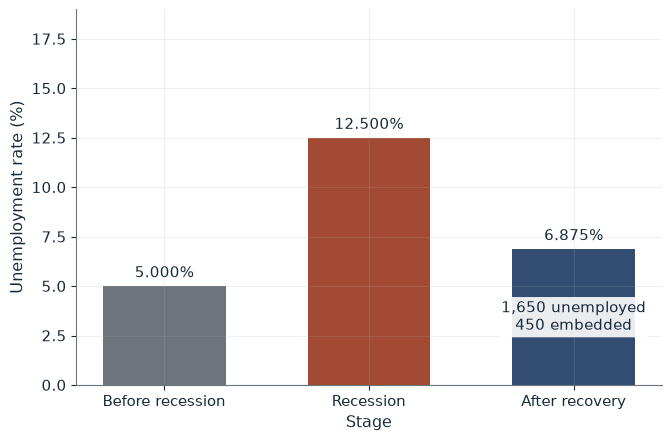

Equilibrium rate after recovery  6.875%
Unemployed after recovery        1,650
Embedded workers                 450
Displaced in the recession       1,800

Worked steps:
  1. u1* = 5 + 0.9 x 0 + 0.25 x (12.5 - 5) = 6.875%
  2. Unemployed = 0.06875 x 24,000 = 1,650
  3. Embedded = 1,650 - 1,200 = 450

u1* = 5 + 0.9 x (5 - 5) + 0.25 x (12.5 - 5) = 5 + 1.875 = 6.875 percent. That is 0.06875 x 24,000 = 1,650 unemployed after demand recovers, 450 more than the original 1,200: the recession has left a scar.


In [8]:
show(hysteresis_picture(gamma=0.25, u0=12.5))

Change one input, `gamma`, and hold the others at the book's values:

In [9]:
sweep(hysteresis_picture, 'gamma', [0.0, 0.08333333333333333, 0.25, 0.5], {'u0': 12.5}, ['Equilibrium rate after recovery', 'Unemployed after recovery', 'Embedded workers'])

gamma | Equilibrium rate after recovery | Unemployed after recovery | Embedded workers
0.0 | 5.000% | 1,200 | 0
0.08333333333333333 | 5.625% | 1,350 | 150
0.25 | 6.875% | 1,650 | 450
0.5 | 8.750% | 2,100 | 900


At gamma = 0.25 the equilibrium rate becomes 6.875 percent, 1,650 unemployed, 450 of them embedded. A program that lowers gamma to 1/12 leaves 5.625 percent, 1,350 unemployed.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

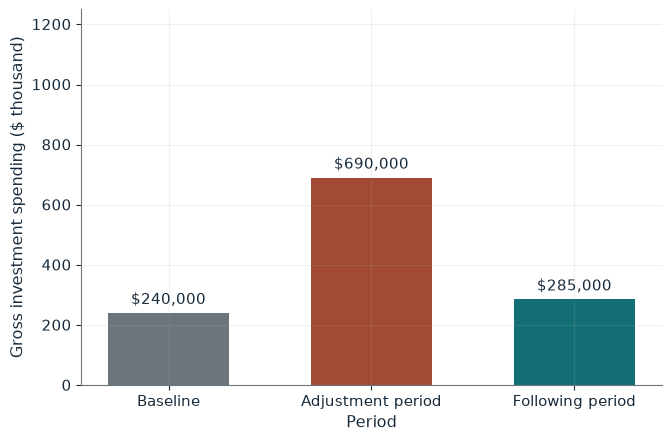

Desired capital before     48.0
Desired capital after      57.0
Baseline spending          $240,000
Adjustment spending        $690,000
Following-period spending  $285,000
Drop after the gap closes  $405,000
Rise in expected output    18.75%

Worked steps:
  1. K0* = 6 x 8 = 48.0; baseline = 0.10 x 48.0 = 4.80 units
  2. K1* = 6 x 9.5 = 57.0
  3. I1 = (57.0 - 48.0) + 4.80 = 13.80 units
  4. Spending = 13.80 x 50,000 = $690,000
  5. Next period = 0.10 x 57.0 = 5.70 units = $285,000

K* = 6 x 8 = 48.0 units, so baseline investment is 0.10 x 48.0 = 4.80 units, or $240,000. With expected output 9.5, K* = 6 x 9.5 = 57.0, and I = (57.0 - 48.0) + 4.80 = 13.80 units, or $690,000. Once capital is 57.0, spending falls back to replacement, 0.10 x 57.0 = 5.70 units or $285,000, a drop of $405,000 while expected output stays at 9.5.


In [10]:
show(accelerator_picture(y1=9.5, v=6))

## Practice

**1.** In the accelerator example, what is gross investment in the period after the gap closes?

<details><summary>Answer</summary>

0.10 x 57 = 5.7 units, and 5.7 x 50,000 = \$285,000.

</details>

**2.** In the multiplier-accelerator example, what is induced investment in period 4?

<details><summary>Answer</summary>

C4 = 0.5 x 55.32 = 27.66, so I4 = 1.2 x (27.66 - 30.6) = -3.528.

</details>

**3.** With gamma = 1/12, how many are unemployed after recovery?

<details><summary>Answer</summary>

5 + 7.5 / 12 = 5.625 percent, and 0.05625 x 24,000 = 1,350.

</details>